In [ ]:
import pandas as pd
import numpy as np
from helpers import *
from preprocessing import *
from implementations import *

In [2]:
data = pd.read_csv("dataset/x_train.csv")
data

,Id,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,...,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,0,53,11,11162015,11,16,2015,1100,2015015629,2015015629,...,1,1,3.0,3.0,4.0,1,1,NaN,NaN,2.0
1,1,33,12,12152015,12,15,2015,1200,2015004387,2015004387,...,9,9,3.0,3.0,4.0,9,9,NaN,NaN,NaN
2,2,20,10,10202015,10,20,2015,1100,2015005638,2015005638,...,4,2,2.0,2.0,3.0,1,1,1.0,2.0,2.0
3,3,42,6,6182015,6,18,2015,1100,2015004694,2015004694,...,2,2,2.0,2.0,3.0,1,1,2.0,2.0,2.0
4,4,24,11,11062015,11,6,2015,1100,2015004673,2015004673,...,9,9,3.0,3.0,4.0,1,1,9.0,9.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328130,328130,49,7,11232015,11,23,2015,1100,2015006796,2015006796,...,2,2,3.0,3.0,4.0,1,1,NaN,NaN,2.0
328131,328131,51,5,6082015,6,8,2015,1100,2015006482,2015006482,...,1,1,3.0,3.0,4.0,1,1,NaN,NaN,1.0
328132,328132,39,10,10202015,10,20,2015,1100,2015004898,2015004898,...,3,2,3.0,3.0,4.0,1,2,2.0,2.0,2.0
328133,328133,33,12,12302015,12,30,2015,1100,2015004449,2015004449,...,3,2,3.0,3.0,4.0,1,1,NaN,NaN,2.0


## Preprocessing

In [3]:
data_clean = preprocessing(data)
data_clean


Colonnes supprimées : Id, _PSU, DISPCODE, SEQNO, IYEAR, IMONTH, IDAY, IDATE, FMONTH, CELLFON3, LANDLINE, SEX, PVTRESD2, CSTATE, CTELENUM, CTELNUM1, CELLFON2, PVTRESD1, _VEGETEX, _VEGRESP, _FRTRESP, _FRUITEX
Colonnes binaires converties de 1,2 en 1,0.
Nombre de colonnes constantes : 1
Colonnes supprimées pour corrélation : ['_STSTR', '_MRACE1', 'HTM4', '_RFDRHV5', 'FC60_', '_RFSEAT3']


,_STATE,NUMADULT,NUMMEN,NUMWOMEN,CADULT,HHADULT,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,...,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_FLSHOT6,_PNEUMO2,_AIDTST3
0,53,2.0,1.0,1.0,0.0,2.0,2.0,1.0,5,88.0,...,1,1,1,3.0,3.0,4.0,1,1.0,1.0,2.0
1,33,2.0,1.0,1.0,0.0,2.0,4.0,88.0,88,88.0,...,9,9,9,3.0,3.0,4.0,9,1.0,1.0,2.0
2,20,2.0,1.0,1.0,0.0,2.0,2.0,77.0,77,88.0,...,2,4,2,2.0,2.0,3.0,1,1.0,2.0,2.0
3,42,2.0,1.0,1.0,0.0,2.0,1.0,88.0,88,88.0,...,2,2,2,2.0,2.0,3.0,1,2.0,2.0,2.0
4,24,1.0,1.0,0.0,0.0,2.0,2.0,88.0,88,88.0,...,2,9,9,3.0,3.0,4.0,1,9.0,9.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328130,49,2.0,1.0,1.0,1.0,2.0,2.0,88.0,88,88.0,...,2,2,2,3.0,3.0,4.0,1,1.0,1.0,2.0
328131,51,2.0,1.0,1.0,1.0,2.0,1.0,88.0,88,88.0,...,1,1,1,3.0,3.0,4.0,1,1.0,1.0,1.0
328132,39,1.0,0.0,1.0,0.0,2.0,3.0,88.0,1,88.0,...,1,3,2,3.0,3.0,4.0,1,2.0,2.0,2.0
328133,33,3.0,2.0,1.0,0.0,2.0,3.0,88.0,88,88.0,...,1,3,2,3.0,3.0,4.0,1,1.0,1.0,2.0


# Functions to implement 

### Linear regression using gradient descent

In [ ]:
# def calculate_mse(e):
#     """Calculate the mse for vector e."""
#     return 1 / 2 * np.mean(e**2)

    
# def compute_gradient(y, tx, w):
#     """Computes the gradient at w.

#     Args:
#         y: numpy array of shape=(N, )
#         tx: numpy array of shape=(N,2)
#         w: numpy array of shape=(2, ). The vector of model parameters.

#     Returns:
#         An numpy array of shape (2, ) (same shape as w), containing the gradient of the loss at w.
#     """

#     err = y - tx.dot(w)
#     grad = -tx.T.dot(err) / len(err)
#     return grad, err


# def gradient_descent(y, tx, initial_w, max_iters, gamma):
#     """The Gradient Descent (GD) algorithm.

#     Args:
#         y: numpy array of shape=(N, )
#         tx: numpy array of shape=(N,2)
#         initial_w: numpy array of shape=(2, ). The initial guess (or the initialization) for the model parameters
#         max_iters: a scalar denoting the total number of iterations of GD
#         gamma: a scalar denoting the stepsize

#     Returns:
#         losses: a list of length max_iters containing the loss value (scalar) for each iteration of GD
#         ws: a list of length max_iters + 1 containing the model parameters as numpy arrays of shape (2, ),
#             for each iteration of GD (as well as the final weights)
#     """
#     # Define parameters to store w and loss
#     ws = [initial_w]
#     losses = []
#     w = initial_w
#     for n_iter in range(max_iters):

#         # compute loss, gradient
#         grad, err = compute_gradient(y, tx, w)
#         loss = calculate_mse(err)
#         # update w by gradient descent
#         w = w - gamma * grad
#         # store w and loss
#         ws.append(w)
#         losses.append(loss)
#         print(
#             "GD iter. {bi}/{ti}: loss={l}, w0={w0}, w1={w1}".format(
#                 bi=n_iter, ti=max_iters - 1, l=loss, w0=w[0], w1=w[1]
#             )
#         )

#     return losses, ws



    

In [5]:
from sklearn.preprocessing import StandardScaler

# Créer une copie des données pour éviter de modifier l'original
data_clean_standardized = data_clean.copy()

# Sélectionner uniquement les colonnes numériques
numeric_columns = data_clean_standardized.select_dtypes(include=['float64', 'int64']).columns

# Appliquer la standardisation
scaler = StandardScaler()
data_clean_standardized[numeric_columns] = scaler.fit_transform(data_clean_standardized[numeric_columns])

print("Les features ont été standardisées.")

Les features ont été standardisées.


In [6]:
# Features
X = data_clean_standardized.to_numpy(dtype=float)

y = pd.read_csv("dataset/y_train.csv")

# Supprimer Id uniquement s'il existe
y = y.drop(columns=["Id"], errors="ignore")

# Convertir y en vecteur 1D si le fichier contient une seule colonne cible
if y.shape[1] == 1:
    y = y.iloc[:, 0]

# Vérifications
print("Shape de X :", X.shape)
print("Shape de y :", y.shape)
print("Nombre de features :", X.shape[1])

assert len(X) == len(y), "X et y doivent avoir le même nombre de lignes."

Shape de X : (328135, 177)
Shape de y : (328135,)
Nombre de features : 177


In [7]:
# Number of features
D = X.shape[1]

# Initialize weights
initial_w = np.zeros(D)

# Hyperparameters
max_iters = 500
gamma = 0.01

# Run GD
losses, ws = gradient_descent(
    y, X, initial_w, max_iters, gamma
)

# Final weights and loss
final_w = ws[-1]

print("Final weights:", final_w)
print("Final loss:", losses[-1])

GD iter. 0/499: loss=0.5, w0=3.1937394486282456e-05, w1=-0.00035791632130369617
GD iter. 1/499: loss=0.4973521508768679, w0=6.141208013559034e-05, w1=-0.0006724366526840852
GD iter. 2/499: loss=0.4951071020376643, w0=8.867108303909342e-05, w1=-0.0009476898390884624
GD iter. 3/499: loss=0.4931991240491798, w0=0.00011393542759158295, w1=-0.0011874297611655065
GD iter. 4/499: loss=0.4915734918033076, w0=0.0001374032160352245, w1=-0.0013950690355559315
GD iter. 5/499: loss=0.4901846134314028, w0=0.00015925229415600676, w1=-0.0015737096911217178
GD iter. 6/499: loss=0.4889944821926578, w0=0.00017964256423315587, w1=-0.001726171092844163
GD iter. 7/499: loss=0.4879713944754788, w0=0.000198717996790585, w1=-0.0018550153606182614
GD iter. 8/499: loss=0.4870888873577807, w0=0.0002166083846885647, w1=-0.0019625705078925556
GD iter. 9/499: loss=0.48632485752770294, w0=0.00023343087637071446, w1=-0.002050951504844985
GD iter. 10/499: loss=0.48566083016323797, w0=0.0002492913194354672, w1=-0.002122

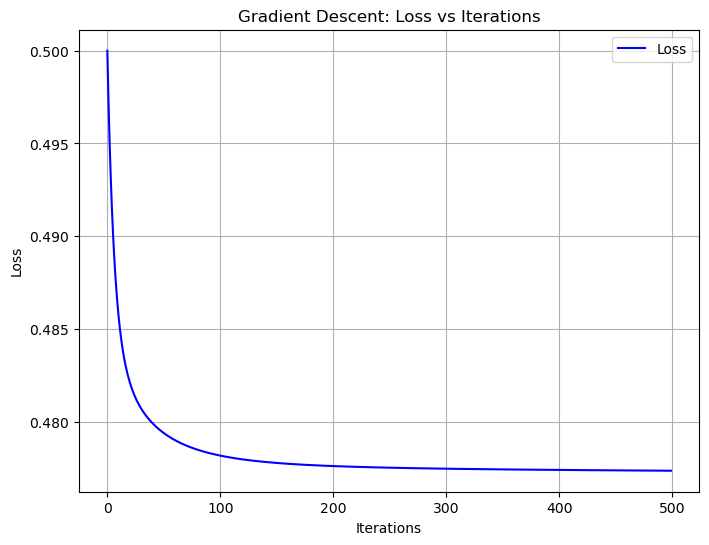

In [8]:
import matplotlib.pyplot as plt

# Plot the loss vs iterations
plt.figure(figsize=(8, 6))
plt.plot(range(len(losses)), losses, label="Loss", color="blue")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Gradient Descent: Loss vs Iterations")
plt.grid(True)
plt.legend()
plt.show()

In [9]:
print("Final weights:", final_w)

Final weights: [ 2.38807051e-03  2.51128065e-03  1.28686882e-02 -1.12847566e-02
  1.39985357e-02  1.10249813e-03  5.53102428e-02 -8.45012300e-03
  6.80733336e-04 -4.33741575e-03 -4.30023911e-03  6.97572048e-03
 -2.20951469e-03  7.89526928e-04 -3.27504254e-02 -1.82293005e-02
 -4.60185698e-03 -8.64038027e-03 -3.60795996e-02 -3.32818952e-02
 -2.69647182e-03 -7.26942810e-03 -7.87624489e-04 -1.83419229e-02
  1.72313929e-03  3.82120929e-04 -1.36301114e-02 -3.06406104e-02
 -3.19973641e-03 -2.15662294e-03  6.56941318e-03 -1.39460220e-04
  1.61659050e-03 -2.15397994e-02  1.95913461e-02 -1.95758872e-03
  8.24034599e-04  1.30416186e-02 -6.94282272e-03  2.83746645e-03
 -5.27530906e-03 -1.75340501e-02 -1.80591331e-03  2.92219502e-03
 -1.24942705e-02  4.95557926e-03  1.34918874e-04 -1.37967179e-02
  7.54622814e-03 -1.16514343e-03  4.49717644e-03  7.06153243e-03
 -3.61929288e-05  3.08543471e-03 -7.04844425e-04  4.90602528e-05
  1.09737156e-03  9.28203271e-04  6.29765438e-03 -2.10978942e-03
 -2.491349

In [10]:
# Calculer les scores prédits
y_scores = X @ final_w

# Transformer les scores en classes -1 et +1
y_pred = np.where(y_scores >= 0, 1, -1)

print(y_pred[:10])

[-1  1 -1 -1  1  1  1  1 -1 -1]


In [11]:
accuracy = np.mean(y_pred == y)
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 62.96%


### Test

In [17]:
# 1. Charger les nouveaux patients
X_test = pd.read_csv("dataset/X_test.csv")

# 2. Enlever la colonne ID si elle existe
X_test = X_test.drop(columns=["Id"], errors="ignore")

# 4. Appliquer le même preprocessing que sur X_train
X_test= preprocessing(X_test)

Colonnes supprimées : _PSU, DISPCODE, SEQNO, IYEAR, IMONTH, IDAY, IDATE, FMONTH, CELLFON3, LANDLINE, SEX, PVTRESD2, CSTATE, CTELENUM, CTELNUM1, CELLFON2, PVTRESD1, _VEGETEX, _VEGRESP, _FRTRESP, _FRUITEX
Colonnes binaires converties de 1,2 en 1,0.
Nombre de colonnes constantes : 1
Colonnes supprimées pour corrélation : ['_STSTR', '_MRACE1', 'HTM4', '_RFDRHV5', 'FC60_', '_RFSEAT3']


In [20]:
from sklearn.preprocessing import StandardScaler

# Créer une copie des données pour éviter de modifier l'original
X_test_standardized = X_test.copy()

# Sélectionner uniquement les colonnes numériques
numeric_columns = X_test_standardized.select_dtypes(include=['float64', 'int64']).columns

# Appliquer la standardisation
scaler = StandardScaler()
X_test_standardized[numeric_columns] = scaler.fit_transform(X_test_standardized[numeric_columns])

print("Les features ont été standardisées.")

Les features ont été standardisées.


In [21]:
# Calculer les scores prédits
y_test_scores = X_test_standardized @ final_w

# Transformer les scores en classes -1 et +1
y_pred_test = np.where(y_test_scores >= 0, 1, -1)
print(y_pred_test[:10])

[ 1 -1 -1  1 -1 -1 -1 -1  1  1]


## Submission file

In [28]:
# Charger les données de test pour récupérer les Id
X_test_df = pd.read_csv("dataset/X_test.csv")

# Vérifier que le nombre de prédictions correspond au nombre d'Id
assert len(y_pred_test) == len(X_test_df), \
    "Le nombre de prédictions ne correspond pas au nombre de lignes de X_test."

# Créer le fichier de soumission avec les Id correspondants
submission = pd.DataFrame({
    "Id": X_test_df["Id"],
    "Prediction": y_pred_test
})

# Enregistrer le fichier
submission.to_csv("sample-submission.csv", index=False)

print("Fichier submission.csv créé !")
print(submission.head())

Fichier submission.csv créé !
       Id  Prediction
0  328135           1
1  328136          -1
2  328137          -1
3  328138           1
4  328139          -1
